In [1]:
import numpy as np
import pandas as pd
import xarray as xr

In [2]:
from data import UncertainDataset, ds_single, ds_pressure

In [3]:
from pathlib import Path

plots = Path("plots")

In [17]:
table = pd.read_csv("table-raw.csv")

In [20]:
from matplotlib import pyplot as plt

def plot_ensemble_mean_spread(
    mean: xr.DataArray, spread: xr.DataArray,
    info: pd.DataFrame,
    plot: Path,
    sample: slice = slice(None),
    title_extra: str = "",
):
    mean, spread = mean.copy(deep=True), spread.copy(deep=True)
    
    fig, ax = plt.subplots(num=1, clear=True)

    m0, m1, m99, m100 = np.nanquantile(mean.values.flatten(), [0.0, 0.01, 0.99, 1.0])
    s99, s100 = np.nanquantile(spread.values.flatten(), [0.99, 1.0])

    months = sorted(set(zip(
        pd.to_datetime(mean.valid_time).year,
        pd.to_datetime(mean.valid_time).month,
    )))
    colours = ["tab:orange", "tab:blue"]
    
    ax.set_title(f"{mean.long_name} ({mean.name}){title_extra}")
    ax.set_xlabel(f"mean [{mean.units}]")
    ax.set_ylabel(f"spread [{spread.units}]")

    data_handles = []

    for (year, month), colour in zip(months, colours):
        data_handles.append(ax.scatter(
            mean.sel(valid_time=f"{year}-{month:02}").values.flatten()[sample],
            spread.sel(valid_time=f"{year}-{month:02}").values.flatten()[sample],
            s=1, label=f"{year}/{month:02}", edgecolor="none", marker=".", c=colour,
        ))

    if m1 != m99:
        ms = m99 - m1
        ax.set_xlim(m1 - ms*0.05, m99 + ms*0.05)
    else:
        ms = m100 - m0
        ax.set_xlim(m0 - ms*0.05, m100 + ms*0.05)
    if s99 != 0.0:
        ss = s99
        ax.set_ylim(0.0 - ss*0.05, s99 + ss*0.05)
    else:
        ss = s100
        ax.set_ylim(0.0 - ss*0.05, s100 + ss*0.05)

    bound_legend = []

    for p, ls in zip(["100%", "99%", "95%"], ["-", "--", ":"]):
        pinfo = info[info["percentile"] == p]
        pick = pinfo["pick"].iloc[0]
        
        if pick == "absolute":
            bound_legend.append(ax.axhline(
                float(pinfo["esabsolute"].iloc[0]), ls=ls, c="red", label=f"{p}: {pick}",
            ))
        elif pick == "relative":
            x = ax.get_xlim()
            x = np.array(sorted(list(x) + [0.0]))
            bound_legend.append(ax.plot(
                x,
                x * float(pinfo["esrelative"].iloc[0][:-1]) / 100 * np.sign(x),
                ls=ls, c="red", label=f"{p}: {pick}",
            )[0])
        elif pick == "quadratic":
            x = ax.get_xlim()
            x = np.linspace(x[0], x[1], num=100)
            q, mi, ma = pinfo[["esquadratic", "min", "max"]].iloc[0]
            bound_legend.append(ax.plot(
                x,
                q - q * (-1.0 + 2.0 * (x - mi) / (ma - mi))**2,
                ls=ls, c="red", label=f"{p}: {pick}",
            )[0])

    bound_legend.append(ax.axhline(
        info["lpabsolute"].iloc[0], ls=":", c="black",
        label=f"linear packing, {info['lpbits'].iloc[0]} bits",
    ))

    fig.legend(handles=data_handles, loc="upper right", markerscale=10)
    ax.legend(handles=bound_legend, loc="upper right")

    plot.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(plot)

    plt.close(fig)

In [6]:
from tqdm import tqdm

  0%|          | 0/226 [00:00<?, ?it/s]/tmp/junityre/26953288/ipykernel_3395027/2971987894.py:47: UserWarning: Attempting to set identical bottom == top == 0.0 results in singular transformations; automatically expanding.
  ax.set_ylim(0.0 - ss*0.05, s100 + ss*0.05)
  0%|          | 1/226 [00:09<34:30,  9.20s/it]/tmp/junityre/26953288/ipykernel_3395027/2971987894.py:47: UserWarning: Attempting to set identical bottom == top == 0.0 results in singular transformations; automatically expanding.
  ax.set_ylim(0.0 - ss*0.05, s100 + ss*0.05)
  1%|          | 2/226 [00:21<41:39, 11.16s/it]/tmp/junityre/26953288/ipykernel_3395027/2971987894.py:47: UserWarning: Attempting to set identical bottom == top == 0.0 results in singular transformations; automatically expanding.
  ax.set_ylim(0.0 - ss*0.05, s100 + ss*0.05)
  1%|▏         | 3/226 [00:32<41:35, 11.19s/it]/tmp/junityre/26953288/ipykernel_3395027/2971987894.py:47: UserWarning: Attempting to set identical bottom == top == 0.0 results in sing

KeyboardInterrupt: 

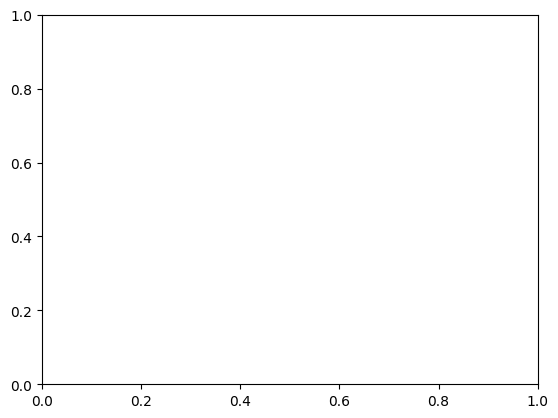

In [21]:
for key in tqdm(sorted(ds_single.mean)):
    plot_ensemble_mean_spread(
        ds_single.mean[key],
        ds_single.spread[key],
        table[(table["var"] == key) & (table["level"] == "single")],
        plots / "single" / f"{key}.png",
        sample=slice(0, None, 1000),
    )

 12%|█▎        | 2/16 [02:47<19:32, 83.75s/it]/tmp/junityre/26953288/ipykernel_3395027/3011464980.py:41: UserWarning: Attempting to set identical left == right == 0.0 results in singular transformations; automatically expanding.
  ax.set_xlim(m0 - ms*0.05, m100 + ms*0.05)
/tmp/junityre/26953288/ipykernel_3395027/3011464980.py:47: UserWarning: Attempting to set identical bottom == top == 0.0 results in singular transformations; automatically expanding.
  ax.set_ylim(0.0 - ss*0.05, s100 + ss*0.05)
 19%|█▉        | 3/16 [04:12<18:13, 84.14s/it]/tmp/junityre/26953288/ipykernel_3395027/3011464980.py:41: UserWarning: Attempting to set identical left == right == 0.0 results in singular transformations; automatically expanding.
  ax.set_xlim(m0 - ms*0.05, m100 + ms*0.05)
/tmp/junityre/26953288/ipykernel_3395027/3011464980.py:47: UserWarning: Attempting to set identical bottom == top == 0.0 results in singular transformations; automatically expanding.
  ax.set_ylim(0.0 - ss*0.05, s100 + ss*0.05

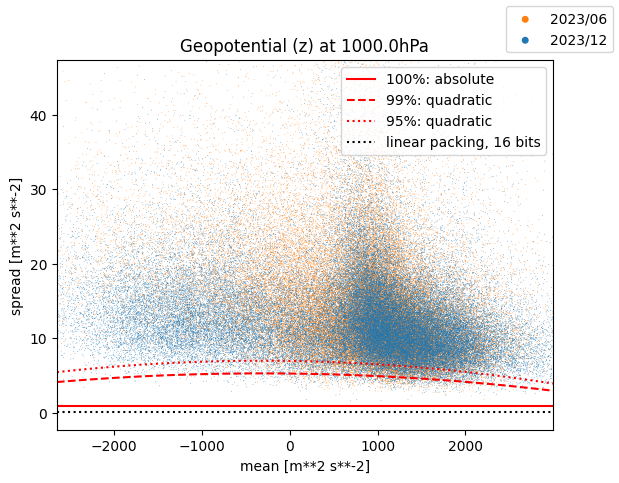

In [8]:
for key in tqdm(sorted(ds_pressure.mean)):
    for pressure in ds_pressure.mean[key].pressure_level.values:
        plot_ensemble_mean_spread(
            ds_pressure.mean[key].sel(pressure_level=pressure),
            ds_pressure.spread[key].sel(pressure_level=pressure),
            table[(table["var"] == key) & (table["level"] == f"{pressure} hPa")],
            plots / "pressure" / f"{key}-{pressure}hPa.png",
            sample=slice(0, None, 1000),
            title_extra=f" at {pressure}hPa",
        )